# Causal Uplift Modeling - Flagship Analysis

**Who should we target?** Not the customers most likely to convert, but those
whose decision actually *changes* because we treated them.

> **Data note.** This notebook runs on the committed **synthetic** Criteo-like
> sample so it executes in seconds and redistributes no proprietary data. The
> synthetic effect is deliberately stronger and cleaner than reality. The
> **headline numbers in the project README are computed on the full, real
> 13.9M-row Criteo dataset** (real ATE on `visit` ≈ **+0.0103**, best-model Qini
> ≈ **0.09**) - reproduce them with `scripts/download_data.py` then
> `scripts/run_experiment.py --use-raw`.

This notebook reproduces the *methodology* end-to-end using the installable
`uplift` package and the committed sample. It covers:

1. The data and the randomized design
2. The average treatment effect (and why it isn't enough)
3. From intent-to-treat to the effect on the *exposed* (CACE / IV)
4. Training four uplift estimators (S/T/X-learner + class transformation)
5. Uplift-specific evaluation (Qini, AUUC, uplift@k)
6. The targeting / business payoff
7. Is the ranking trustworthy? Paired bootstrap, uncertainty, and calibration

> For the full ~13.9M-row dataset, run `python scripts/download_data.py` then
> `python scripts/run_experiment.py --use-raw`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift import config, data, evaluation, pipeline
from uplift.config import ExperimentConfig

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
plt.rcParams["figure.figsize"] = (7, 4)


## 1. The data

A randomized trial: ~85% of users are treated, the rest are control. Features `f0`-`f11` are anonymized; outcomes are `visit` and the rarer `conversion`.

In [2]:
df = data.load_sample()
print(f"{len(df):,} rows")
df.head()

50,000 rows


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,exposure,conversion,visit
0,0.3047,-1.0400,0.7505,0.9406,-1.9510,-1.3022,0.1278,-0.3162,-0.0168,-0.8530,0.8794,0.7778,1,0,0,0
1,0.0660,1.1272,0.4675,-0.8593,0.3688,-0.9589,0.8785,-0.0499,-0.1849,-0.6809,1.2225,-0.1545,1,0,0,1
2,-0.4283,-0.3521,0.5323,0.3654,0.4127,0.4308,2.1416,-0.4064,-0.5122,-0.8138,0.6160,1.1290,0,0,0,0
3,-0.1139,-0.8402,-0.8245,0.6506,0.7433,0.5432,-0.6655,0.2322,0.1167,0.2187,0.8714,0.2236,1,0,0,0
4,0.6789,0.0676,0.2891,0.6313,-1.4572,-0.3197,-0.4704,-0.6389,-0.2751,1.4949,-0.8658,0.9683,1,0,0,0


In [3]:
rates = pd.DataFrame({
    "share":  df[config.TREATMENT_COL].value_counts(normalize=True),
    "visit_rate": df.groupby(config.TREATMENT_COL)[config.VISIT_COL].mean(),
    "conversion_rate": df.groupby(config.TREATMENT_COL)[config.CONVERSION_COL].mean(),
})
rates.index = ["control (0)", "treated (1)"]
rates

,share,visit_rate,conversion_rate
control (0),0.1512,0.0620,0.0257
treated (1),0.8488,0.0714,0.0298


## 2. The average treatment effect - and its limits

The ATE tells us the campaign *on average* lifts visits. A two-proportion z-test confirms it's real. But an average hides who is actually moved - that is the gap uplift modeling fills.

In [4]:
from statsmodels.stats.proportion import proportions_ztest

t = df[config.TREATMENT_COL]; y = df[config.VISIT_COL]
ate = y[t == 1].mean() - y[t == 0].mean()
count = np.array([y[t == 1].sum(), y[t == 0].sum()])
nobs  = np.array([(t == 1).sum(), (t == 0).sum()])
stat, pval = proportions_ztest(count, nobs)
print(f"ATE on visit: {ate:+.4f}")
print(f"two-proportion z-test: z={stat:.1f}, p={pval:.2e}")

ATE on visit: +0.0093
two-proportion z-test: z=2.9, p=3.34e-03


## 2b. From intent-to-treat to effect-on-the-exposed (CACE)

The ATE above is an **intent-to-treat (ITT)** effect: the effect of being
*targeted*. But only a fraction of targeted users were actually *exposed* to an
ad (`exposure`) - the campaign has a compliance problem, so the ITT is diluted by
everyone who was targeted but never shown an ad.

Using randomized assignment as an **instrument** for exposure, the Wald estimator
rescales the ITT by the compliance rate to recover the **complier average causal
effect (CACE / LATE)** - the effect on the users the ad actually reached. This is
valid under one-sided non-compliance (a control user is never exposed). See
`src/uplift/iv.py`.

In [5]:
from uplift import iv

res = iv.estimate_cace(
    df[config.VISIT_COL], df[config.TREATMENT_COL], df[config.EXPOSURE_COL]
)
print(f"First stage (exposure rate among the assigned): {res.itt_d:.3f}")
print(f"ITT  - effect of being targeted:  {res.itt_y:+.4f}")
print(f"CACE - effect on the exposed:     {res.cace:+.4f}  "
      f"95% CI [{res.lo:+.4f}, {res.hi:+.4f}]")

First stage (exposure rate among the assigned): 0.352
ITT  - effect of being targeted:  +0.0093
CACE - effect on the exposed:     +0.0266  95% CI [+0.0098, +0.0441]


## 3. Train four uplift estimators

All share one `fit(X, y, t) -> predict_uplift(X)` interface. One call runs the stratified split, fits every model, and evaluates them.

In [6]:
cfg = ExperimentConfig(outcome="visit", base_learner="lgbm", random_state=42)
result = pipeline.run_experiment(df, cfg)
result.metrics

,qini,auuc,uplift@10%,uplift@30%,weighted_avg_uplift
model,,,,,
S-learner,0.1014,0.1044,0.1025,0.0445,0.0083
Class transformation,0.0830,0.0859,0.0701,0.0405,0.0091
X-learner,0.0677,0.0705,0.0403,0.0282,0.0091
T-learner,0.0630,0.0654,0.0371,0.0307,0.0087


## 4. Uplift-specific evaluation

Accuracy/ROC-AUC are meaningless here - we never see the individual treatment effect. Instead we rank users by predicted uplift and measure the **incremental** conversions captured, against the real treated/control arms.

* **Qini / AUUC** - area between the model's gain curve and random targeting (normalized: 0 = random, 1 = oracle).
* The dashed line is random targeting; higher and earlier is better.

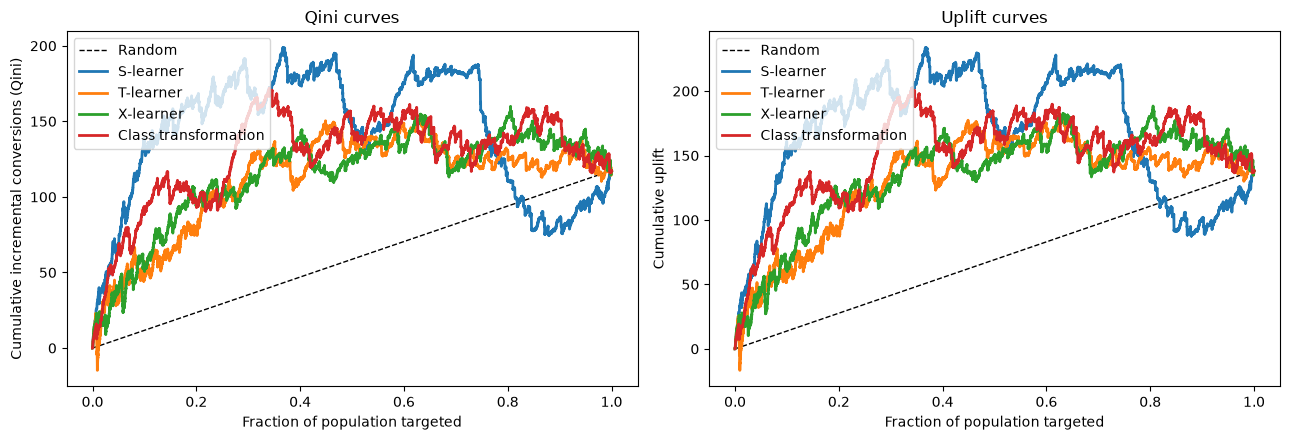

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
evaluation.plot_qini(result.qini_curves, ax=axes[0])
evaluation.plot_uplift_curve(result.uplift_curves, ax=axes[1])
plt.tight_layout(); plt.show()

## 5. The targeting payoff

How much uplift do we capture if we only treat the top *k%* the model recommends? The top decile carries far more incremental value than the average user - the entire point of uplift-based targeting.

In [8]:
best_name = result.metrics.index[0]
u = result.predictions[best_name]
# Reproduce the same held-out split the pipeline used, to view uplift by depth.
X_tr, X_te, y_tr, y_te, t_tr, t_te = data.train_test_split_uplift(df, cfg)
ks = [0.05, 0.10, 0.20, 0.30, 0.50, 1.0]
rows = [{"top_k": f"{int(k*100)}%",
         "uplift": evaluation.uplift_at_k(y_te, t_te, u, k)} for k in ks]
decile = pd.DataFrame(rows)
print(f"Best model: {best_name}  |  overall ATE = {result.ate:+.4f}")
decile

Best model: S-learner  |  overall ATE = +0.0092


,top_k,uplift
0,5%,0.1043
1,10%,0.1025
2,20%,0.0636
3,30%,0.0445
4,50%,0.0237
5,100%,0.0092


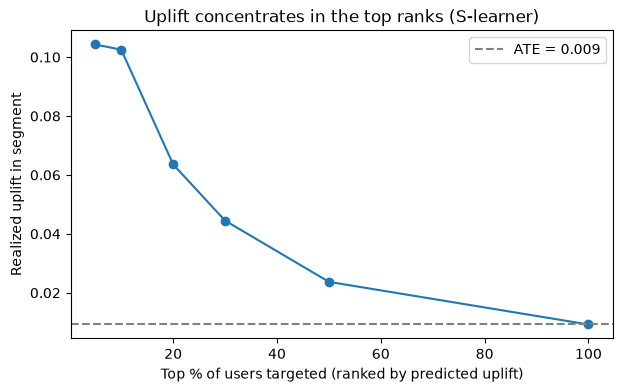

In [9]:
ax = plt.subplot()
ax.plot([int(k*100) for k in ks], [r["uplift"] for r in rows], "o-")
ax.axhline(result.ate, ls="--", color="grey", label=f"ATE = {result.ate:.3f}")
ax.set_xlabel("Top % of users targeted (ranked by predicted uplift)")
ax.set_ylabel("Realized uplift in segment")
ax.set_title(f"Uplift concentrates in the top ranks ({best_name})")
ax.legend(); plt.show()

## 6. Is the ranking trustworthy? Uncertainty + calibration

Two rigor checks that separate a real causal analysis from a leaderboard score:

* **Bootstrap CI** on Qini - a single number is noise without an interval.
* **Calibration** - do *predicted* uplifts match *realized* uplifts per bin? Ranking correctly is necessary; being calibrated is the stronger claim.

In [10]:
ci = evaluation.bootstrap_metric(y_te, t_te, u, "qini", n_boot=200, random_state=0)
print(f"{best_name} Qini = {ci['point']:.3f}  "
      f"(95% CI [{ci['lo']:.3f}, {ci['hi']:.3f}], se={ci['se']:.3f})")

S-learner Qini = 0.101  (95% CI [0.050, 0.151], se=0.026)


In [11]:
# Paired bootstrap: is the leaderboard ordering real, or within noise? Every model
# is scored on the *same* resamples, so the difference vs. the best cancels shared
# noise. `tied=True` => that model is statistically indistinguishable from the best.
cmp = evaluation.compare_models_bootstrap(
    y_te, t_te, result.predictions, "qini", n_boot=300, random_state=0
)
cmp.round(4)

,point,lo,hi,diff_vs_best,diff_lo,diff_hi,tied
model,,,,,,,
S-learner,0.1014,0.0485,0.1510,0.0000,0.0000,0.0000,True
Class transformation,0.0830,0.0355,0.1294,0.0184,-0.0382,0.0756,True
X-learner,0.0677,0.0134,0.1227,0.0337,-0.0226,0.0883,True
T-learner,0.0630,0.0095,0.1222,0.0384,-0.0170,0.0921,True


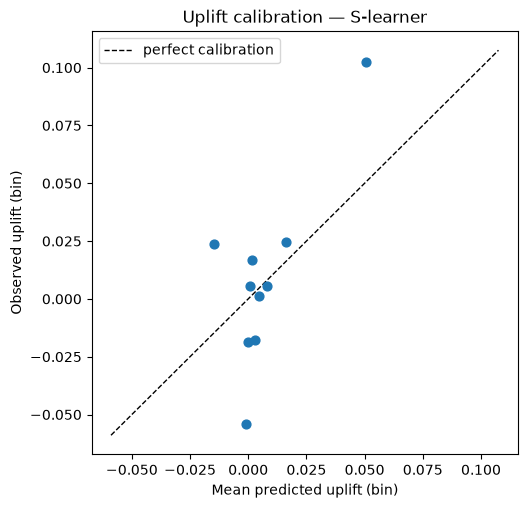

,bin,n,predicted_uplift,observed_uplift
0,0,1500,-0.0147,0.0237
1,1,1500,-0.0008,-0.0540
2,2,1500,0.0001,-0.0186
3,3,1500,0.0007,0.0058
4,4,1500,0.0016,0.0167
5,5,1500,0.0028,-0.0178
6,6,1500,0.0047,0.0013
7,7,1500,0.0082,0.0056
8,8,1500,0.0162,0.0246
9,9,1500,0.0505,0.1025


In [12]:
calib = evaluation.uplift_calibration(y_te, t_te, u, bins=10)
evaluation.plot_calibration(calib, title=f"Uplift calibration - {best_name}")
plt.show()
calib

## Takeaways

* The campaign has a small but real **average** effect, and uplift models
  **concentrate** it - the top-ranked users carry several times the average
  uplift, so targeting them (not everyone) is where the ROI is.
* On the **real** 13.9M-row Criteo data the effect is subtle (ATE ≈ +0.0103,
  best-model Qini ≈ 0.09, top-decile uplift ≈ 6× the average) - see the README.
  The synthetic sample here shows the same *shape* with a louder signal.
* Evaluation uses **causally valid** metrics (Qini/AUUC against the RCT arms),
  reports **bootstrap uncertainty**, and checks **calibration** - all
  unit-tested in `tests/`.

See the `src/uplift` package for the implementation and the other notebooks for
deeper EDA, meta-learner comparisons, and the full business case.
